In [1]:
from ultralytics import YOLO
from getpass import getpass
from roboflow import Roboflow
import shutil
import cv2

In [ ]:
rf = Roboflow(api_key=getpass("Roboflow API key: "))
project = rf.workspace("jhazmine-therese-roque-biwst").project("emotion-detection-ooj7h")
dataset = project.version(4).download("yolov8", location="datasets/emotions")
print(dataset.location)

train: 4487 frames, 0 images without frames
{'Angry': 642, 'Disgusted': 644, 'Fearful': 634, 'Happy': 639, 'Neutral': 640, 'Sad': 640, 'Surprised': 648}
valid: 550 frames, 0 images without frames
{'Angry': 79, 'Disgusted': 78, 'Fearful': 83, 'Happy': 73, 'Neutral': 74, 'Sad': 85, 'Surprised': 78}
test: 566 frames, 0 images without frames
{'Angry': 80, 'Disgusted': 78, 'Fearful': 83, 'Happy': 91, 'Neutral': 85, 'Sad': 75, 'Surprised': 74}


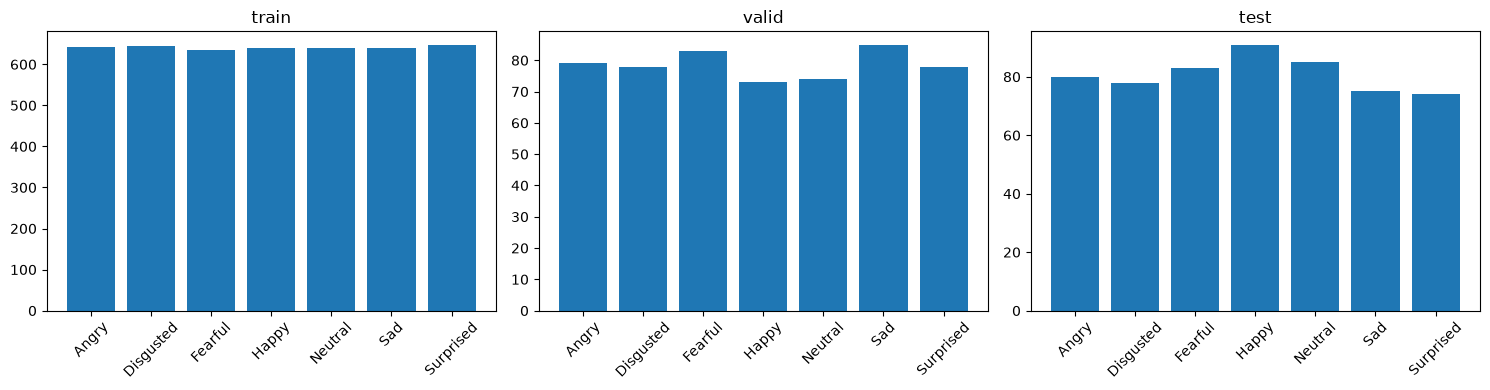

In [2]:
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt

DATASET_DIR = Path("datasets/emotions")
NAMES = ["Angry", "Disgusted", "Fearful", "Happy", "Neutral", "Sad", "Surprised"]

def count_classes(split):
    counts, empty = Counter(), 0
    for f in (DATASET_DIR / split / "labels").glob("*.txt"):
        lines = f.read_text().strip().splitlines()
        if not lines:
            empty += 1
        for line in lines:
            counts[int(line.split()[0])] += 1
    return counts, empty

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, split in zip(axes, ["train", "valid", "test"]):
    counts, empty = count_classes(split)
    print(f"{split}: {sum(counts.values())} frames, {empty} images without frames")
    print({NAMES[i]: counts[i] for i in range(7)})
    ax.bar(NAMES, [counts[i] for i in range(7)])
    ax.set_title(split)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [3]:
def apply_clahe(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    clahe = cv2.createCLAHE(clipLimit=1.5, tileGridSize=(2, 2))
    gray = clahe.apply(gray)
    return cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

In [4]:
PROCESSED_DIR = Path("datasets/emotions_clahe")

for split in ["train", "valid", "test"]:
    out_images = PROCESSED_DIR / split / "images"
    out_images.mkdir(parents=True, exist_ok=True)

    shutil.copytree(DATASET_DIR / split / "labels",
                    PROCESSED_DIR / split / "labels",
                    dirs_exist_ok=True)

    for path in (DATASET_DIR / split / "images").glob("*.jpg"):
        img = cv2.imread(str(path))
        cv2.imwrite(str(out_images / path.name), apply_clahe(img))

shutil.copy(DATASET_DIR / "data.yaml", PROCESSED_DIR / "data.yaml")
print("Ready")

Ready


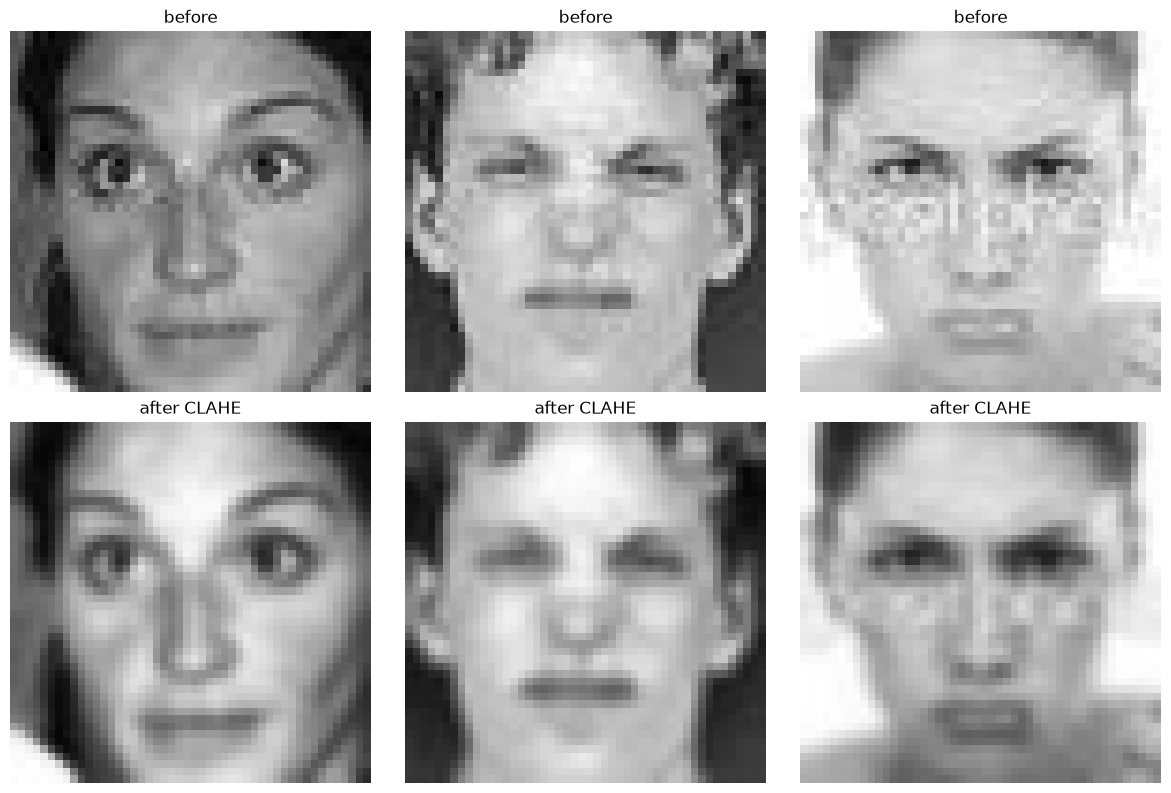

In [6]:
import random

random.seed(42)
files = random.sample(list((DATASET_DIR / "train" / "images").glob("*.jpg")), 3)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, path in enumerate(files):
    before = cv2.imread(str(path))
    after = cv2.imread(str(PROCESSED_DIR / "train" / "images" / path.name))
    axes[0, i].imshow(cv2.cvtColor(before, cv2.COLOR_BGR2RGB))
    axes[0, i].set_title("before")
    axes[1, i].imshow(cv2.cvtColor(after, cv2.COLOR_BGR2RGB))
    axes[1, i].set_title("after CLAHE")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
plt.tight_layout()
plt.savefig("preprocessing_example.png", dpi=100)
plt.show()

In [7]:
for name, data in [("baseline", "datasets/emotions/data.yaml"),
                   ("clahe", "datasets/emotions_clahe/data.yaml")]:
    model = YOLO(f"runs/detect/{name}/weights/best.pt")
    m = model.val(data=data, split="test", imgsz=96, device="cpu", name=f"test_{name}")
    print(name, "mAP50:", round(m.box.map50, 3), "mAP50-95:", round(m.box.map, 3),
          "precision:", round(m.box.mp, 3), "recall:", round(m.box.mr, 3))

Ultralytics 8.4.216 🚀 Python-3.14.2 torch-2.15.0+cu132 CPU (AMD EPYC 7763 64-Core Processor)
Model summary (fused): 73 layers, 3,134,165 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1.8±1.3 MB/s, size: 1.2 KB)
val: Scanning /workspaces/edu-grafika-lab3/datasets/emotions/test/labels... 566 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 566/566 1.6Kit/s 0.4s0.1ss
val: New cache created: /workspaces/edu-grafika-lab3/datasets/emotions/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 11.3it/s 3.2s0.2s
                   all        566        566      0.472      0.726      0.615       0.59
                 Angry         80         80      0.317      0.625      0.418      0.372
             Disgusted         78         78      0.522      0.923      0.802       0.79
               Fearful         83         83      0.384      0.518      0.418      0.387
             

test2.jpg baseline Happy 0.7
test2.jpg clahe Happy 0.35
test2.jpg clahe Disgusted 0.28
test3.JPG baseline Fearful 0.34
test5.jpeg baseline Happy 0.6


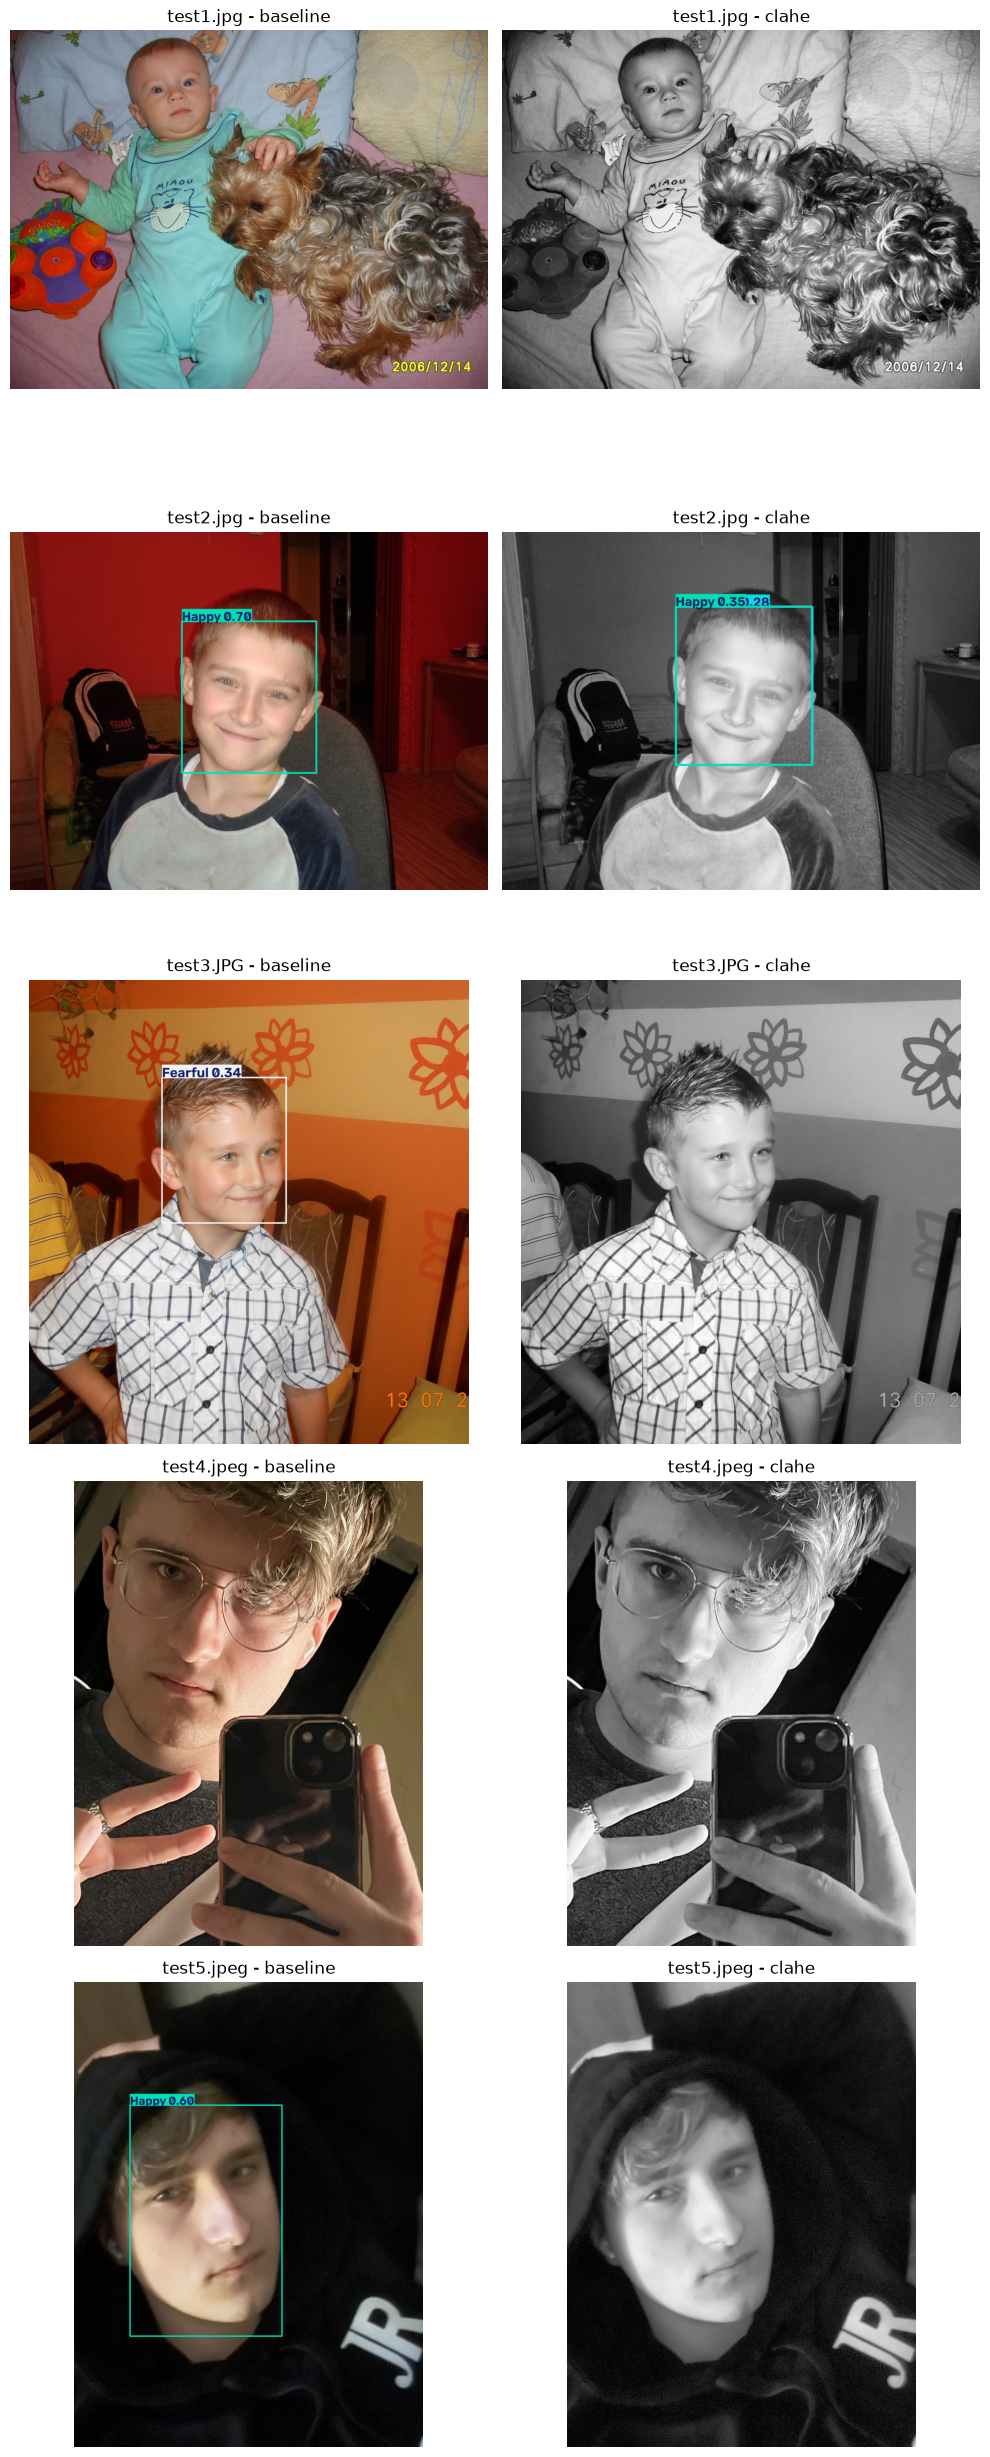

In [17]:
paths = [p for p in sorted(Path("samples").iterdir())
         if p.suffix.lower() in (".jpg", ".jpeg", ".JPG")]

model_b = YOLO("runs/detect/baseline/weights/best.pt")
model_c = YOLO("runs/detect/clahe/weights/best.pt")

fig, axes = plt.subplots(len(paths), 2, figsize=(10, 5 * len(paths)), squeeze=False)

for row, path in enumerate(paths):
    img = cv2.imread(str(path))
    res_b = model_b.predict(img, imgsz=96, conf=0.25, verbose=False)[0]
    res_c = model_c.predict(apply_clahe(img), imgsz=96, conf=0.25, verbose=False)[0]

    for col, (res, title) in enumerate([(res_b, "baseline"), (res_c, "clahe")]):
        axes[row, col].imshow(cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB))
        axes[row, col].set_title(f"{path.name} - {title}")
        axes[row, col].axis("off")
        for box in res.boxes:
            print(path.name, title, NAMES[int(box.cls)], round(float(box.conf), 2))

plt.tight_layout()
plt.savefig("results/prediction_examples.png", dpi=100)
plt.show()

test1.jpg 96 baseline [('Neutral', 0.18), ('Surprised', 0.08)]
test1.jpg 96 clahe [('Happy', 0.24), ('Happy', 0.1), ('Surprised', 0.08)]
test1.jpg 160 baseline [('Surprised', 0.12)]
test1.jpg 160 clahe [('Happy', 0.1), ('Neutral', 0.1), ('Happy', 0.06)]
test1.jpg 320 baseline [('Fearful', 0.31), ('Sad', 0.18), ('Angry', 0.18)]
test1.jpg 320 clahe [('Fearful', 0.59), ('Happy', 0.2), ('Happy', 0.1)]
test2.jpg 96 baseline [('Happy', 0.7)]
test2.jpg 96 clahe [('Happy', 0.35), ('Disgusted', 0.28)]
test2.jpg 160 baseline [('Happy', 0.64), ('Sad', 0.06)]
test2.jpg 160 clahe [('Happy', 0.84), ('Neutral', 0.1), ('Fearful', 0.07)]
test2.jpg 320 baseline [('Happy', 0.7), ('Happy', 0.48), ('Fearful', 0.17)]
test2.jpg 320 clahe [('Happy', 0.65)]
test3.JPG 96 baseline [('Fearful', 0.34), ('Neutral', 0.2), ('Surprised', 0.18)]
test3.JPG 96 clahe [('Surprised', 0.19)]
test3.JPG 160 baseline [('Fearful', 0.16), ('Angry', 0.15), ('Sad', 0.12)]
test3.JPG 160 clahe [('Surprised', 0.06), ('Surprised', 0.06

(np.float64(-0.5), np.float64(3023.5), np.float64(4031.5), np.float64(-0.5))

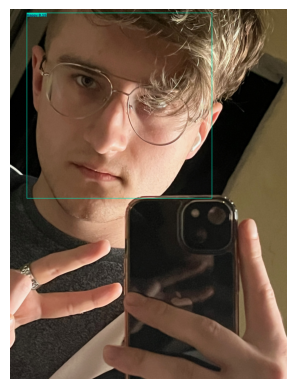

In [19]:
for path in paths:
    img = cv2.imread(str(path))
    for size in [96, 160, 320]:
        for title, model, im in [("baseline", model_b, img), ("clahe", model_c, apply_clahe(img))]:
            res = model.predict(im, imgsz=size, conf=0.05, verbose=False)[0]
            found = [(NAMES[int(b.cls)], round(float(b.conf), 2)) for b in res.boxes]
            print(path.name, size, title, found[:3])
res = model_b.predict(cv2.imread("samples/test4.jpeg"), imgsz=96, conf=0.05, verbose=False)[0]
plt.imshow(cv2.cvtColor(res.plot(line_width=4), cv2.COLOR_BGR2RGB)); plt.axis("off")

In [20]:
for name, data in [("baseline", "datasets/emotions/data.yaml"),
                   ("clahe", "datasets/emotions_clahe/data.yaml")]:
    model = YOLO(f"runs/detect/{name}/weights/best.pt")
    m = model.val(data=data, split="test", imgsz=96, device="cpu", name=f"test_{name}")
    print(name, "mAP50:", round(m.box.map50, 3), "mAP50-95:", round(m.box.map, 3),
          "precision:", round(m.box.mp, 3), "recall:", round(m.box.mr, 3))

Ultralytics 8.4.216 🚀 Python-3.14.2 torch-2.15.0+cu132 CPU (AMD EPYC 7763 64-Core Processor)
Model summary (fused): 73 layers, 3,134,165 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 557.7±697.2 MB/s, size: 13.3 KB)
val: Scanning /workspaces/edu-grafika-lab3/datasets/emotions/test/labels.cache... 566 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 566/566 148.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 10.5it/s 3.4s0.1s
                   all        566        566      0.472      0.726      0.615       0.59
                 Angry         80         80      0.317      0.625      0.418      0.372
             Disgusted         78         78      0.522      0.923      0.802       0.79
               Fearful         83         83      0.384      0.518      0.418      0.387
                 Happy         91         91      0.728      0.714      0.833       0.82
     

In [22]:
import hashlib

def hashes(split):
    return {hashlib.md5(p.read_bytes()).hexdigest()
            for p in (DATASET_DIR / split / "images").glob("*.jpg")}

print("same photos train/test:", len(hashes("train") & hashes("test")))

same photos train/test: 0
